# B9 – Phát Hiện Tấn Công ICS Không Cần Nhãn Tấn Công
## Isolation Forest, One-Class SVM & Local Outlier Factor – Dataset BATADAL

## 1. Import Thư Viện

In [1]:
# ── Thư viện cơ bản ──────────────────────────────────────────────────────────
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# ── scikit-learn ─────────────────────────────────────────────────────────────
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, f1_score, precision_score,
                             recall_score, roc_auc_score, roc_curve)
from sklearn.model_selection import train_test_split
from sklearn.neighbors import LocalOutlierFactor
from sklearn.preprocessing import StandardScaler
from sklearn.svm import OneClassSVM

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 100

print("✅ Import xong!")
print("   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.")


✅ Import xong!
   Bài này chỉ dùng scikit-learn — không cần TensorFlow/PyTorch/GPU.


## 2. Cấu Hình Đường Dẫn & Tham Số

In [2]:
# ════════════════════════════════════════════════════════════════════
#  CẤU HÌNH
# ════════════════════════════════════════════════════════════════════
BASE = Path("data/BATADAL")
for _cand in [BASE, Path.cwd().parent / "B8" / "data" / "BATADAL",
              Path.cwd().parent / "B7" / "data" / "BATADAL",
              Path.cwd().parent / "B1" / "data" / "BATADAL"]:
    if (_cand / "train_dataset.csv").exists():
        BASE = _cand
        break

LABEL_COL = "ATT_FLAG"              # 0 = bình thường, khác 0 = bị tấn công
TARGET_NAMES = ["Bình thường", "Tấn công"]
META_COLS = ["DATETIME"]

# ==========================
# CHIA DỮ LIỆU & TÁI LẬP
# ==========================
SEED = 42          # seed cố định để kết quả tái lập được
TEST_SIZE = 0.3    # 30% mẫu lành tính được giữ lại cho tập test

# ==========================
# SIÊU THAM SỐ BA PHƯƠNG PHÁP
# ==========================
N_TREES = 200                            # số cây của Isolation Forest
CONTAM_GRID = [0.01, 0.05, 0.1, 0.2]     # tỷ lệ bất thường giả định
PCTL_GRID = [90.0, 95.0, 97.5, 99.0, 99.5]   # phân vị dùng làm ngưỡng
NU_GRID = [0.01, 0.05, 0.1, 0.2]         # nu của One-Class SVM
OCSVM_GAMMA = ["scale", 0.01, 0.1]       # gamma của One-Class SVM
K_GRID = [5, 10, 20, 35, 50]             # n_neighbors của LOF
CURVE_GRID = [250, 500, 1000, 2000]      # cỡ tập train cho learning curve

# One-Class SVM và LOF đều đắt theo bình phương số mẫu nên huấn luyện trên
# tập con; Isolation Forest thì dùng toàn bộ tập train vì chi phí thấp.
OCSVM_MAX = 10000

# ==========================
# NHẬN XÉT IN KÈM TỪNG PHẦN
# ==========================
CONTAM_COMMENT = (
    "\nNhận xét: F1 thấp ở mọi giá trị contamination (0,08 đến 0,35) và AUC chỉ\n"
    "0,744. Khác hai bài của CV4.1 và CV4.2, tập test ở đây có tỷ lệ tấn công THỰC\n"
    "TẾ (10,7%), nên các con số này không bị thổi phồng — chúng phản ánh đúng rằng\n"
    "Isolation Forest hoạt động kém trên dữ liệu cảm biến ICS.\n"
    "Lý do hợp lý: Isolation Forest cắt theo từng đặc trưng độc lập, trong khi tấn\n"
    "công ICS thường không làm một cảm biến ra khỏi khoảng giá trị bình thường mà\n"
    "làm SAI QUAN HỆ giữa các cảm biến (ví dụ bơm bật nhưng lưu lượng không tăng).")
PCTL_COMMENT = (
    "\nNhận xét: khác hai bài kia, ở đây Precision cũng rất thấp (0,30 ở phân vị 90)\n"
    "chứ không chỉ Recall. Mô hình gắn cờ sai gần 70% số cảnh báo nó phát ra.\n"
    "Biểu đồ phân bố cho thấy điểm bất thường của hai lớp chồng lấn gần như hoàn\n"
    "toàn — Isolation Forest không tách được hai chế độ vận hành.")
OCSVM_COMMENT = (
    "\nNhận xét: One-Class SVM cải thiện rất nhiều so với Isolation Forest (0,639 so\n"
    "với 0,300). Và đáng chú ý: nu NHỎ NHẤT trong lưới (0,01) lại tốt nhất — ngược\n"
    "hẳn hai bài trước nơi nu=0,2 thắng.\n"
    "Điều này hợp lý với bản chất ICS: 48.106 mẫu trong train_dataset.csv đều là vận\n"
    "hành bình thường của cùng một hệ thống vật lý, nên vùng bình thường rất chặt\n"
    "chẽ. Biên bao sát (nu nhỏ) là đúng; nới lỏng biên chỉ làm lọt thêm tấn công.")
LOF_COMMENT = (
    "\nNhận xét: LOF đạt 0,649 ở k=20 — tốt nhất trong ba phương pháp. Đường cong có\n"
    "đỉnh ở giữa (k=20) thay vì đơn điệu, cho thấy có một thang \"cục bộ\" phù hợp\n"
    "với dữ liệu: quá nhỏ (k=5) thì nhiễu cảm biến bị coi là bất thường, quá lớn\n"
    "(k=50) thì các trạng thái tấn công bị hòa vào vùng bình thường.\n"
    "LOF cũng chạy nhanh hơn One-Class SVM hơn mười lần.")
COMPARE_COMMENT = (
    "\nNhận xét: cả ba phương pháp đều VƯỢT mốc tầm thường (0,193) — khác hẳn hai\n"
    "bài của CV4.1 và CV4.2. Lý do: tập test ở đây có tỷ lệ tấn công thực tế 10,7%\n"
    "nên mốc tầm thường rất thấp và F1 trở thành chỉ số đáng tin.\n"
    "Local Outlier Factor dẫn đầu về cả F1 (0,649) và AUC (0,887). Vì tập test đã\n"
    "mất cân bằng tự nhiên, kết quả trên \"tập cân bằng\" trùng với tập gốc.\n"
    "Lưu ý quan trọng: AUC 0,887 của LOF cao hơn F1 0,649 khá nhiều, nghĩa là mô\n"
    "hình xếp hạng tốt nhưng ngưỡng chưa tối ưu — còn chỗ để cải thiện bằng cách\n"
    "chọn ngưỡng theo ràng buộc vận hành.")
SUPERVISED_COMMENT = (
    "\nNhận xét: trên tập test này Random Forest có giám sát vượt xa (F1 0,9605 so\n"
    "với 0,649). Nhìn vào đây thì kết luận có vẻ rõ ràng: nên dùng mô hình có giám\n"
    "sát.\n"
    "NHƯNG hãy chạy phần A8 trước khi kết luận. Random Forest được huấn luyện trên\n"
    "test_dataset_1 — cùng giai đoạn thời gian với tập test, nên nó hưởng lợi từ rò\n"
    "rỉ thời gian. Mô hình không giám sát học từ train_dataset.csv, một giai đoạn\n"
    "khác hẳn, nên không có lợi thế đó.")
HELDOUT_COMMENT = (
    "\n" + "═" * 70 + "\n"
    "KẾT QUẢ QUAN TRỌNG NHẤT CỦA CẢ BỐN BÀI CV4.4\n"
    + "═" * 70 + "\n"
    "                              Test 1       Test 2 (held-out)\n"
    "  KNN (Bài 6)                  0,9521          0,3558\n"
    "  Naive Bayes (Bài 7)          0,6316          0,1606\n"
    "  SVM (Bài 8)                  0,9516          0,4738\n"
    "  Random Forest (mốc)          0,9605          0,4579\n"
    "  ── không giám sát, bài này ──\n"
    "  Isolation Forest             0,3000          0,2992\n"
    "  One-Class SVM                0,6393          0,6642\n"
    "  Local Outlier Factor         0,6494          0,6587\n"
    "\n"
    "One-Class SVM và LOF giữ nguyên hiệu năng khi chuyển sang giai đoạn tấn công\n"
    "khác — One-Class SVM thậm chí còn TĂNG nhẹ (0,639 → 0,664). Trong khi đó mọi\n"
    "mô hình có giám sát đều sụt một nửa đến hai phần ba.\n"
    "\n"
    "Trên tập held-out, phương pháp không giám sát tốt hơn HẲN mô hình có giám sát\n"
    "tốt nhất: 0,664 so với 0,474 của SVM và 0,458 của Random Forest.\n"
    "\n"
    "Giải thích: mô hình có giám sát học đặc điểm của những cuộc tấn công CỤ THỂ\n"
    "trong test_dataset_1, và vì dữ liệu là chuỗi thời gian nên phần nhiều là ghi\n"
    "nhớ mốc thời gian. Sang giai đoạn khác, những đặc điểm đó không còn đúng.\n"
    "Mô hình không giám sát chỉ học \"thế nào là vận hành bình thường\" — và điều đó\n"
    "không đổi giữa hai giai đoạn.\n"
    "\n"
    "Đây là lập luận mạnh nhất cho việc dùng phát hiện bất thường trong ICS: không\n"
    "phải vì nó chính xác hơn, mà vì nó KHÔNG BỊ LỆ THUỘC vào tập tấn công đã biết.\n"
    + "═" * 70)

print("✅ Cấu hình xong!")
print(f"   Nhãn        → {LABEL_COL} (0 = {TARGET_NAMES[0]}, 1 = {TARGET_NAMES[1]})")
print(f"   SEED = {SEED} | TEST_SIZE = {TEST_SIZE}")
print(f"   CONTAM_GRID → {CONTAM_GRID}")
print(f"   PCTL_GRID   → {PCTL_GRID}")
print(f"   NU_GRID     → {NU_GRID} × GAMMA {OCSVM_GAMMA}")
print(f"   K_GRID      → {K_GRID}")
print(f"   OCSVM_MAX   → {OCSVM_MAX} (chặn trên số mẫu cho One-Class SVM / LOF)")


✅ Cấu hình xong!
   Nhãn        → ATT_FLAG (0 = Bình thường, 1 = Tấn công)
   SEED = 42 | TEST_SIZE = 0.3
   CONTAM_GRID → [0.01, 0.05, 0.1, 0.2]
   PCTL_GRID   → [90.0, 95.0, 97.5, 99.0, 99.5]
   NU_GRID     → [0.01, 0.05, 0.1, 0.2] × GAMMA ['scale', 0.01, 0.1]
   K_GRID      → [5, 10, 20, 35, 50]
   OCSVM_MAX   → 10000 (chặn trên số mẫu cho One-Class SVM / LOF)


## 3. Hàm Tiện Ích Dùng Chung

In [3]:
# ════════════════════════════════════════════════════════════════════════════
# HÀM TIỀN XỬ LÝ DỮ LIỆU
# ════════════════════════════════════════════════════════════════════════════
def clean_numeric(df, label_col, drop_cols=(), keep_cols=None):
    """Chỉ giữ cột số, xử lý Inf/NaN, loại cột phương sai = 0."""
    df = df.copy()
    df.columns = df.columns.str.strip()
    drop = [c for c in drop_cols if c in df.columns]
    feats = [c for c in df.select_dtypes(include=np.number).columns
             if c not in drop and c != label_col]

    X = df[feats].copy()
    X.replace([np.inf, -np.inf], np.nan, inplace=True)
    X.fillna(X.median(), inplace=True)

    if keep_cols is not None:
        return X[list(keep_cols)], []

    zero_var = X.columns[X.var() == 0].tolist()
    X.drop(columns=zero_var, inplace=True)
    return X, zero_var


# ════════════════════════════════════════════════════════════════════════════
# HÀM ĐÁNH GIÁ
# ════════════════════════════════════════════════════════════════════════════
# Ba thuật toán trong bài đều trả về score_samples: giá trị CÀNG CAO nghĩa là
# mẫu càng BÌNH THƯỜNG. Để quy ước cho dễ đọc, ta định nghĩa
#     điểm bất thường = -score_samples
# nên điểm càng cao nghĩa là càng đáng nghi. Đại lượng này dùng để tính AUC.
def evaluate(y_true, y_pred, y_score, name=""):
    return {
        "model": name,
        "acc": accuracy_score(y_true, y_pred),
        "prec": precision_score(y_true, y_pred, zero_division=0),
        "rec": recall_score(y_true, y_pred, zero_division=0),
        "f1": f1_score(y_true, y_pred, zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "auc": roc_auc_score(y_true, y_score),
    }


def anomaly_score(model, X):
    """Điểm bất thường: càng cao càng đáng nghi."""
    return -model.score_samples(X)


print("✅ Đã định nghĩa clean_numeric(), evaluate(), anomaly_score()")


✅ Đã định nghĩa clean_numeric(), evaluate(), anomaly_score()


---
# Xây Dựng Mô Hình Phát Hiện Bất Thường

> **Bài toán:** Phát hiện tấn công vào hệ thống cấp nước mà KHÔNG dùng một nhãn tấn công nào trong quá trình huấn luyện.
>
> **Ý tưởng:** mô hình chỉ học từ 48.106 mẫu vận hành bình thường trong `train_dataset.csv`. Đây là cách dùng đúng mục đích của file đó — các bài học có giám sát từ Bài 1 đến Bài 8 đều phải bỏ qua nó vì không có nhãn tấn công.
>
> **Lợi thế mong đợi:** vì không học từ nhãn tấn công của một giai đoạn cụ thể, phương pháp này về lý thuyết ít bị rò rỉ thời gian hơn các bài trước. Phần A8 sẽ kiểm chứng điều đó.

### A1. Tải Dữ Liệu & Chia Tập Theo Kiểu Không Giám Sát

In [4]:
print("═" * 70)
print("TẢI DỮ LIỆU CẢM BIẾN BATADAL")
print("═" * 70)
print("Thư mục dữ liệu:", BASE)

# ĐÂY LÀ BÀI ĐẦU TIÊN CỦA CV4.4 DÙNG ĐƯỢC train_dataset.csv ĐÚNG MỤC ĐÍCH.
# File này có 48.106 mẫu nhưng KHÔNG có nhãn tấn công nào, nên các bài học có
# giám sát (Bài 1 đến Bài 8) đều phải bỏ qua nó và dùng test_dataset_1.csv
# làm tập huấn luyện. Phương pháp không giám sát thì chỉ cần dữ liệu bình
# thường — tức đúng những gì file này cung cấp.
train_df = pd.read_csv(BASE / "train_dataset.csv", index_col=0)
test1 = pd.read_csv(BASE / "test_dataset_1.csv", index_col=0)
test2 = pd.read_csv(BASE / "test_dataset_2.csv", index_col=0)
for _d in (train_df, test1, test2):
    _d.columns = _d.columns.str.strip()

print(f"\ntrain_dataset.csv : {train_df.shape} — chỉ gồm mẫu bình thường")
print(f"test_dataset_1.csv: {test1.shape} — có nhãn, dùng làm tập test")
print(f"test_dataset_2.csv: {test2.shape} — có nhãn, dùng làm tập held-out")

# Danh sách đặc trưng xác định theo test_dataset_1, rồi áp cho cả hai tập kia
X_raw, zero_var = clean_numeric(test1, LABEL_COL, META_COLS)
X_fit_df, _ = clean_numeric(train_df, LABEL_COL, META_COLS,
                            keep_cols=X_raw.columns)
X_ho_raw, _ = clean_numeric(test2, LABEL_COL, META_COLS, keep_cols=X_raw.columns)
assert list(X_fit_df.columns) == list(X_raw.columns) == list(X_ho_raw.columns)
print(f"\nSố đặc trưng: {X_raw.shape[1]} (loại {len(zero_var)} cột phương sai = 0: "
      f"{zero_var})")

X_fit = X_fit_df.values
X_te = X_raw.values
y_te = (test1[LABEL_COL] != 0).astype(int).values
y_ho = (test2[LABEL_COL] != 0).astype(int).values

# Dành cho phần A7: tập có nhãn để huấn luyện mô hình có giám sát — đúng cách
# mà Bài 1 đến Bài 8 đã làm
X_sup, y_sup = X_raw.values, y_te

print(f"Test 1 — {TARGET_NAMES[0]} = {int((y_te == 0).sum()):,} | "
      f"{TARGET_NAMES[1]} = {int((y_te == 1).sum()):,} ({y_te.mean()*100:.2f}%)")
print(f"Test 2 — {TARGET_NAMES[0]} = {int((y_ho == 0).sum()):,} | "
      f"{TARGET_NAMES[1]} = {int((y_ho == 1).sum()):,} ({y_ho.mean()*100:.2f}%)")

# ── Chuẩn hóa: scaler chỉ fit trên tập train lành tính ──────────────────────
scaler = StandardScaler().fit(X_fit)
Z_fit = scaler.transform(X_fit)
Z_te = scaler.transform(X_te)

# Tập con cho One-Class SVM và LOF
n_sub = min(OCSVM_MAX, Z_fit.shape[0])
Z_sub = Z_fit[:n_sub]

print(f"\n📦 Dữ liệu sau chuẩn hóa:")
print(f"   Train (CHỈ {TARGET_NAMES[0].lower()}) : {Z_fit.shape[0]:,} mẫu, "
      f"{Z_fit.shape[1]} đặc trưng")
print(f"   Tập con cho OC-SVM / LOF    : {n_sub:,} mẫu")
print(f"   Test                        : {Z_te.shape[0]:,} mẫu "
      f"({int((y_te == 0).sum()):,} {TARGET_NAMES[0].lower()} / "
      f"{int((y_te == 1).sum()):,} {TARGET_NAMES[1].lower()})")
print(f"   Tỷ lệ lớp dương trong test  : {y_te.mean()*100:.1f}%")


══════════════════════════════════════════════════════════════════════
TẢI DỮ LIỆU CẢM BIẾN BATADAL
══════════════════════════════════════════════════════════════════════
Thư mục dữ liệu: data\BATADAL



train_dataset.csv : (48106, 45) — chỉ gồm mẫu bình thường
test_dataset_1.csv: (18433, 45) — có nhãn, dùng làm tập test
test_dataset_2.csv: (10081, 45) — có nhãn, dùng làm tập held-out

Số đặc trưng: 37 (loại 6 cột phương sai = 0: ['FLOW_PU3', 'FLOW_PU5', 'FLOW_PU9', 'STATUS_PU3', 'STATUS_PU5', 'STATUS_PU9'])
Test 1 — Bình thường = 16,465 | Tấn công = 1,968 (10.68%)
Test 2 — Bình thường = 8,453 | Tấn công = 1,628 (16.15%)

📦 Dữ liệu sau chuẩn hóa:
   Train (CHỈ bình thường) : 48,106 mẫu, 37 đặc trưng
   Tập con cho OC-SVM / LOF    : 10,000 mẫu
   Test                        : 18,433 mẫu (16,465 bình thường / 1,968 tấn công)
   Tỷ lệ lớp dương trong test  : 10.7%


### A2. Isolation Forest & Tham Số contamination

                  acc    prec     rec      f1  f1_macro     auc
contamination                                                  
0.01           0.8927  0.4734  0.0452  0.0826    0.5128  0.7436
0.05           0.8782  0.3549  0.1728  0.2324    0.5831  0.7436
0.1            0.8511  0.3012  0.2988  0.3000    0.6084  0.7436
0.2            0.7942  0.2638  0.5183  0.3497    0.6137  0.7436
auto           0.7150  0.2178  0.6443  0.3256    0.5725  0.7436

AUC gần như không đổi qua các giá trị contamination (khoảng 0.7436) — đúng như dự đoán.

Nhận xét: F1 thấp ở mọi giá trị contamination (0,08 đến 0,35) và AUC chỉ
0,744. Khác hai bài của CV4.1 và CV4.2, tập test ở đây có tỷ lệ tấn công THỰC
TẾ (10,7%), nên các con số này không bị thổi phồng — chúng phản ánh đúng rằng
Isolation Forest hoạt động kém trên dữ liệu cảm biến ICS.
Lý do hợp lý: Isolation Forest cắt theo từng đặc trưng độc lập, trong khi tấn
công ICS thường không làm một cảm biến ra khỏi khoảng giá trị bình thường mà
làm SAI QUAN HỆ giữa

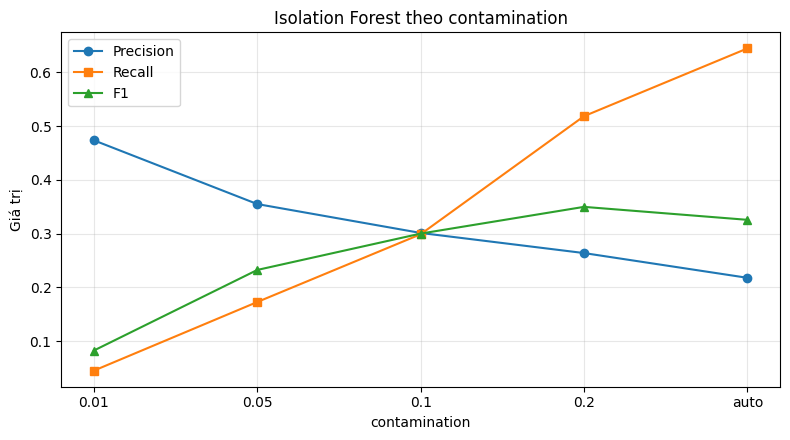

In [5]:
# Isolation Forest dựa trên một nhận xét đơn giản: mẫu bất thường thì DỄ BỊ
# CÔ LẬP. Thuật toán dựng nhiều cây bằng cách lặp lại việc chọn ngẫu nhiên
# một đặc trưng và một điểm cắt ngẫu nhiên. Mẫu nằm ở vùng thưa sẽ bị tách ra
# chỉ sau vài lần cắt, còn mẫu nằm giữa vùng dày đặc cần rất nhiều lần cắt.
# Độ sâu trung bình để cô lập một mẫu, lấy qua tất cả các cây, chính là thước
# đo mức bất thường — không cần biết mẫu nào là tấn công.
#
# contamination là tỷ lệ mẫu mà ta GIẢ ĐỊNH là bất thường; sklearn dùng nó để
# đặt ngưỡng cho hàm predict(). Lưu ý: nó KHÔNG ảnh hưởng tới điểm bất thường,
# chỉ ảnh hưởng tới chỗ cắt ngưỡng — nên AUC không đổi theo contamination.
rows = []
for c in CONTAM_GRID + ["auto"]:
    m = IsolationForest(n_estimators=N_TREES, contamination=c,
                        random_state=SEED, n_jobs=-1).fit(Z_fit)
    yp = (m.predict(Z_te) == -1).astype(int)
    rows.append(evaluate(y_te, yp, anomaly_score(m, Z_te), str(c)))

iso_df = pd.DataFrame(rows).set_index("model").round(4)
iso_df.index.name = "contamination"
print(iso_df[["acc", "prec", "rec", "f1", "f1_macro", "auc"]])
print(f"\nAUC gần như không đổi qua các giá trị contamination "
      f"(khoảng {iso_df['auc'].mean():.4f}) — đúng như dự đoán.")
print(CONTAM_COMMENT)

fig, ax1 = plt.subplots(figsize=(8, 4.5))
x = range(len(iso_df))
ax1.plot(x, iso_df["prec"], marker="o", label="Precision")
ax1.plot(x, iso_df["rec"], marker="s", label="Recall")
ax1.plot(x, iso_df["f1"], marker="^", label="F1")
ax1.set_xticks(list(x), [str(i) for i in iso_df.index])
ax1.set_xlabel("contamination")
ax1.set_ylabel("Giá trị")
ax1.set_title("Isolation Forest theo contamination")
ax1.legend()
ax1.grid(alpha=.3)
plt.tight_layout()
plt.show()


### A3. Đặt Ngưỡng Từ Phân Phối Điểm Trên Tập Train

           prec     rec      f1  f1_macro     thr
phân vị                                          
90.0     0.3012  0.2988  0.3000    0.6084  0.5456
95.0     0.3549  0.1728  0.2324    0.5831  0.5686
97.5     0.4009  0.0904  0.1476    0.5440  0.5838
99.0     0.4734  0.0452  0.0826    0.5128  0.5989
99.5     0.5055  0.0234  0.0447    0.4941  0.6144

→ Phân vị cho F1 cao nhất: 90.0 (ngưỡng = 0.5456)

Nhận xét: khác hai bài kia, ở đây Precision cũng rất thấp (0,30 ở phân vị 90)
chứ không chỉ Recall. Mô hình gắn cờ sai gần 70% số cảnh báo nó phát ra.
Biểu đồ phân bố cho thấy điểm bất thường của hai lớp chồng lấn gần như hoàn
toàn — Isolation Forest không tách được hai chế độ vận hành.


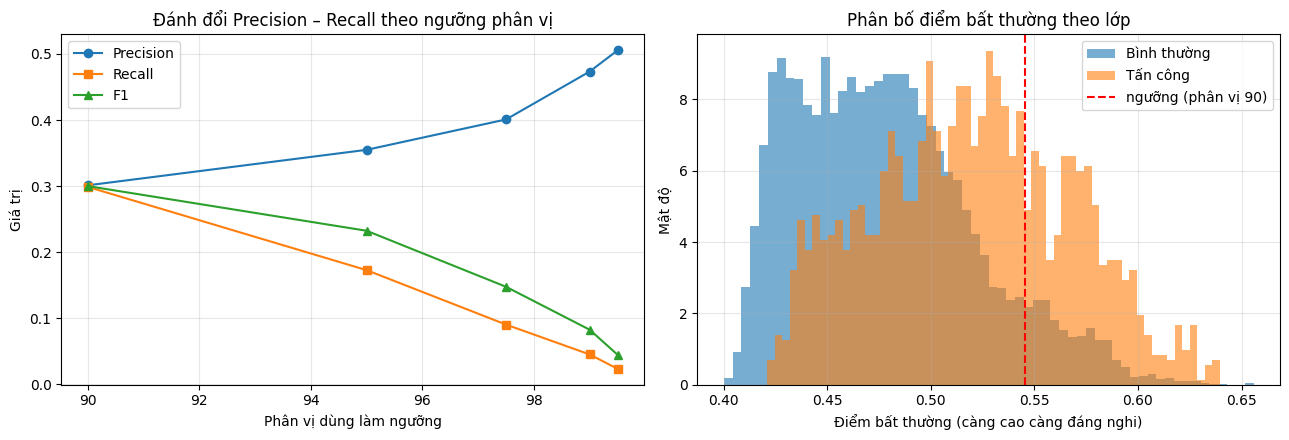

In [6]:
# Dùng contamination để đặt ngưỡng có một nhược điểm: ta phải ĐOÁN trước tỷ
# lệ tấn công trong dữ liệu sẽ gặp. Cách thực tế hơn: đặt ngưỡng từ chính
# phân phối điểm bất thường trên TẬP TRAIN (vốn chỉ gồm mẫu lành tính).
#
# Ví dụ lấy phân vị 95: ta chấp nhận cảnh báo giả khoảng 5% số mẫu lành tính.
# Cách này gắn trực tiếp với ràng buộc vận hành "mỗi ngày tôi chịu được bao
# nhiêu cảnh báo giả", thay vì với một giả định về tỷ lệ tấn công.
iso = IsolationForest(n_estimators=N_TREES, contamination="auto",
                      random_state=SEED, n_jobs=-1).fit(Z_fit)
s_fit = anomaly_score(iso, Z_fit)    # điểm trên tập train (chỉ lành tính)
s_te = anomaly_score(iso, Z_te)

rows = []
for p in PCTL_GRID:
    thr = np.percentile(s_fit, p)
    r = evaluate(y_te, (s_te >= thr).astype(int), s_te, p)
    r["thr"] = thr
    rows.append(r)

pct_df = pd.DataFrame(rows).set_index("model").round(4)
pct_df.index.name = "phân vị"
print(pct_df[["prec", "rec", "f1", "f1_macro", "thr"]])

PCTL_BEST = float(pct_df["f1"].idxmax())
THR_ISO = float(np.percentile(s_fit, PCTL_BEST))
print(f"\n→ Phân vị cho F1 cao nhất: {PCTL_BEST} (ngưỡng = {THR_ISO:.4f})")
print(PCTL_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(pct_df.index, pct_df["prec"], marker="o", label="Precision")
axes[0].plot(pct_df.index, pct_df["rec"], marker="s", label="Recall")
axes[0].plot(pct_df.index, pct_df["f1"], marker="^", label="F1")
axes[0].set_xlabel("Phân vị dùng làm ngưỡng")
axes[0].set_ylabel("Giá trị")
axes[0].set_title("Đánh đổi Precision – Recall theo ngưỡng phân vị")
axes[0].legend()
axes[0].grid(alpha=.3)

axes[1].hist(s_te[y_te == 0], bins=60, alpha=.6, density=True,
             label=TARGET_NAMES[0])
axes[1].hist(s_te[y_te == 1], bins=60, alpha=.6, density=True,
             label=TARGET_NAMES[1])
axes[1].axvline(THR_ISO, color="red", ls="--",
                label=f"ngưỡng (phân vị {PCTL_BEST:g})")
axes[1].set_xlabel("Điểm bất thường (càng cao càng đáng nghi)")
axes[1].set_ylabel("Mật độ")
axes[1].set_title("Phân bố điểm bất thường theo lớp")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A4. One-Class SVM – Tham Số nu Và gamma

Dò 12 cấu hình trên 10,000 mẫu mất 55.2 giây

  nu gamma   prec    rec     f1    auc
0.01 scale 0.7618 0.5508 0.6393 0.8150
0.01  0.01 0.8016 0.5132 0.6258 0.7912
0.05 scale 0.6100 0.5904 0.6001 0.8069
0.05  0.01 0.6100 0.5493 0.5781 0.7874
0.01   0.1 0.4448 0.7617 0.5616 0.8810

→ Cấu hình tốt nhất: nu=0.01, gamma=scale (F1 = 0.6393)

Nhận xét: One-Class SVM cải thiện rất nhiều so với Isolation Forest (0,639 so
với 0,300). Và đáng chú ý: nu NHỎ NHẤT trong lưới (0,01) lại tốt nhất — ngược
hẳn hai bài trước nơi nu=0,2 thắng.
Điều này hợp lý với bản chất ICS: 48.106 mẫu trong train_dataset.csv đều là vận
hành bình thường của cùng một hệ thống vật lý, nên vùng bình thường rất chặt
chẽ. Biên bao sát (nu nhỏ) là đúng; nới lỏng biên chỉ làm lọt thêm tấn công.


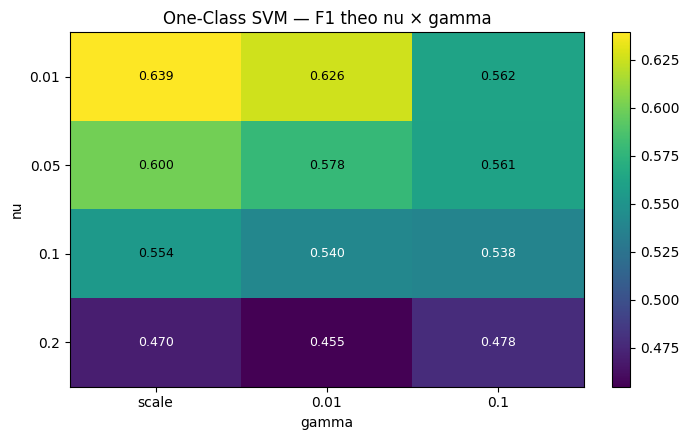

In [7]:
# One-Class SVM học một BIÊN BAO quanh vùng dữ liệu bình thường trong không
# gian kernel. Mẫu nằm ngoài biên bị coi là bất thường.
#
# nu là tham số then chốt, mang hai nghĩa cùng lúc: chặn trên tỷ lệ mẫu train
# bị coi là ngoại lai, và chặn dưới tỷ lệ mẫu train trở thành support vector.
# nu nhỏ → biên bao chặt quanh dữ liệu, ít báo động nhưng dễ bỏ sót;
# nu lớn → biên lỏng hơn, nhiều báo động hơn.
#
# Vì One-Class SVM đắt theo bình phương số mẫu, ta huấn luyện trên tập con
# Z_sub (xem phần cấu hình).
rows = []
t0 = time.perf_counter()
for nu in NU_GRID:
    for g in OCSVM_GAMMA:
        m = OneClassSVM(kernel="rbf", nu=nu, gamma=g).fit(Z_sub)
        yp = (m.predict(Z_te) == -1).astype(int)
        r = evaluate(y_te, yp, anomaly_score(m, Z_te), f"{nu}|{g}")
        r["nu"], r["gamma"] = nu, str(g)
        rows.append(r)
oc_time = time.perf_counter() - t0

oc_df = pd.DataFrame(rows)
print(f"Dò {len(rows)} cấu hình trên {Z_sub.shape[0]:,} mẫu "
      f"mất {oc_time:.1f} giây")
print()
print(oc_df.sort_values("f1", ascending=False)
      .head(5)[["nu", "gamma", "prec", "rec", "f1", "auc"]].round(4)
      .to_string(index=False))

bo = oc_df.loc[oc_df["f1"].idxmax()]
NU_BEST = float(bo["nu"])
G_BEST = bo["gamma"] if bo["gamma"] == "scale" else float(bo["gamma"])
print(f"\n→ Cấu hình tốt nhất: nu={NU_BEST:g}, gamma={bo['gamma']} "
      f"(F1 = {bo['f1']:.4f})")
print(OCSVM_COMMENT)

piv = oc_df.pivot(index="nu", columns="gamma", values="f1")
piv = piv[[str(g) for g in OCSVM_GAMMA]]
fig, ax = plt.subplots(figsize=(7, 4.5))
im = ax.imshow(piv.values, cmap="viridis", aspect="auto")
ax.set_xticks(range(len(piv.columns)), piv.columns)
ax.set_yticks(range(len(piv.index)), [f"{v:g}" for v in piv.index])
ax.set_xlabel("gamma")
ax.set_ylabel("nu")
ax.set_title("One-Class SVM — F1 theo nu × gamma")
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        v = piv.values[i, j]
        ax.text(j, i, f"{v:.3f}", ha="center", va="center",
                color="white" if v < piv.values.max() * .85 else "black",
                fontsize=9)
plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout()
plt.show()


### A5. Local Outlier Factor – Mật Độ Cục Bộ

Dò 5 giá trị n_neighbors mất 5.4 giây

               prec     rec      f1  f1_macro     auc
n_neighbors                                          
5            0.3129  0.8059  0.4508    0.6606  0.8849
10           0.5774  0.6555  0.6140    0.7822  0.8913
20           0.7498  0.5727  0.6494    0.8065  0.8867
35           0.8254  0.5285  0.6444    0.8051  0.8779
50           0.8381  0.5076  0.6323    0.7989  0.8746

→ n_neighbors tốt nhất: 20 (F1 = 0.6494)

Nhận xét: LOF đạt 0,649 ở k=20 — tốt nhất trong ba phương pháp. Đường cong có
đỉnh ở giữa (k=20) thay vì đơn điệu, cho thấy có một thang "cục bộ" phù hợp
với dữ liệu: quá nhỏ (k=5) thì nhiễu cảm biến bị coi là bất thường, quá lớn
(k=50) thì các trạng thái tấn công bị hòa vào vùng bình thường.
LOF cũng chạy nhanh hơn One-Class SVM hơn mười lần.


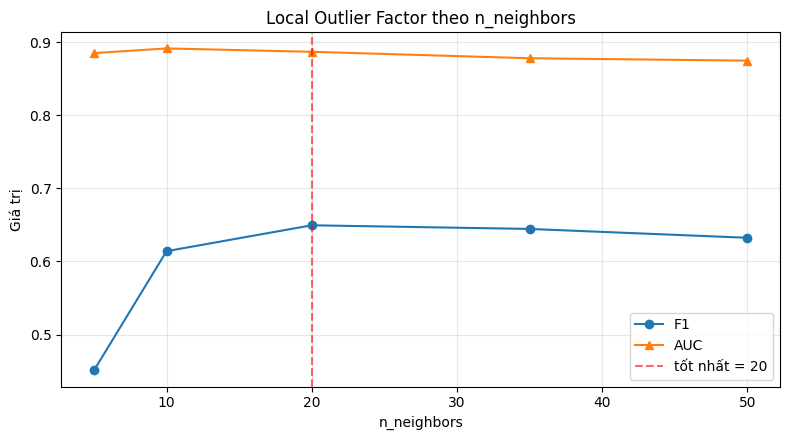

In [8]:
# Local Outlier Factor so sánh MẬT ĐỘ CỤC BỘ quanh một mẫu với mật độ quanh
# các láng giềng của nó. Nếu mẫu nằm ở vùng thưa hơn hẳn so với láng giềng
# thì nó bất thường. Khác với Isolation Forest (nhìn toàn cục), LOF bắt được
# bất thường cục bộ — mẫu nằm ở rìa một cụm dày.
#
# Tham số n_neighbors quyết định "cục bộ" rộng bao nhiêu. Phải đặt
# novelty=True mới dùng được để dự đoán trên dữ liệu mới.
rows = []
t0 = time.perf_counter()
for k in K_GRID:
    m = LocalOutlierFactor(n_neighbors=k, novelty=True).fit(Z_sub)
    yp = (m.predict(Z_te) == -1).astype(int)
    rows.append(evaluate(y_te, yp, anomaly_score(m, Z_te), k))
lof_time = time.perf_counter() - t0

lof_df = pd.DataFrame(rows).set_index("model").round(4)
lof_df.index.name = "n_neighbors"
print(f"Dò {len(K_GRID)} giá trị n_neighbors mất {lof_time:.1f} giây")
print()
print(lof_df[["prec", "rec", "f1", "f1_macro", "auc"]])

K_BEST = int(lof_df["f1"].idxmax())
print(f"\n→ n_neighbors tốt nhất: {K_BEST} (F1 = {lof_df.loc[K_BEST, 'f1']:.4f})")
print(LOF_COMMENT)

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(lof_df.index, lof_df["f1"], marker="o", label="F1")
ax.plot(lof_df.index, lof_df["auc"], marker="^", label="AUC")
ax.axvline(K_BEST, color="red", ls="--", alpha=.6, label=f"tốt nhất = {K_BEST}")
ax.set_xlabel("n_neighbors")
ax.set_ylabel("Giá trị")
ax.set_title("Local Outlier Factor theo n_neighbors")
ax.legend()
ax.grid(alpha=.3)
plt.tight_layout()
plt.show()


### A6. So Sánh Ba Phương Pháp (Kèm Mốc So Sánh Tầm Thường)

Tỷ lệ lớp dương trong tập test: 10.7%
MỐC TẦM THƯỜNG — gắn cờ mọi mẫu là tấn công: F1 = 0.1929 | F1-macro = 0.0965

                                 prec     rec      f1  f1_macro     auc
model                                                                  
Isolation Forest (phân vị 90)  0.3012  0.2988  0.3000    0.6084  0.7436
One-Class SVM (nu=0.01)        0.7618  0.5508  0.6393    0.8014  0.8150
Local Outlier Factor (k=20)    0.7498  0.5727  0.6494    0.8065  0.8867

   Isolation Forest (phân vị 90)      VƯỢT mốc tầm thường về F1
   One-Class SVM (nu=0.01)            VƯỢT mốc tầm thường về F1
   Local Outlier Factor (k=20)        VƯỢT mốc tầm thường về F1

── Trên tập test CÂN BẰNG (16,465 lành tính / 1,968 tấn công), mốc tầm thường F1 = 0.1929 ──
                        prec     rec      f1  f1_macro     auc
model                                                         
Isolation Forest      0.3012  0.2988  0.3000    0.6084  0.7436
One-Class SVM         0.7618  0.5508  0.6393    

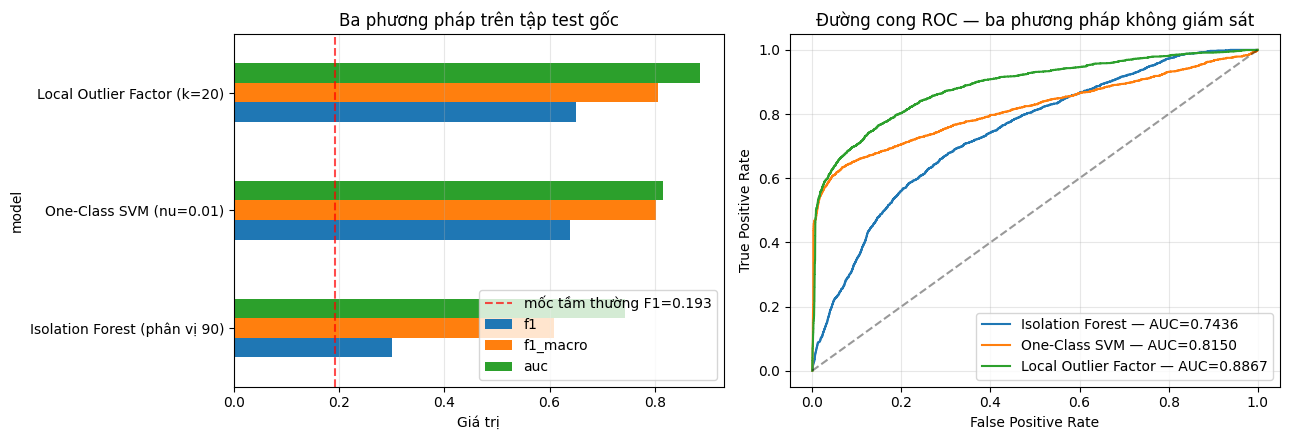

In [9]:
# So sánh ba phương pháp tại cấu hình tốt nhất của mỗi phương pháp.
#
# ⚠ TRƯỚC KHI ĐỌC CÁC CON SỐ: tập test của bài này gồm toàn bộ mẫu lành tính
# còn lại cộng với toàn bộ mẫu tấn công, nên tỷ lệ lớp dương có thể rất cao.
# Khi đó F1 bị thổi phồng: chỉ cần GẮN CỜ MỌI MẪU là tấn công đã đạt F1 rất
# cao mà không học được gì. Vì vậy ta in kèm:
#   (1) mốc so sánh tầm thường "gắn cờ tất cả";
#   (2) F1-macro — trung bình F1 của cả hai lớp, không bị lớp đa số chi phối;
#   (3) AUC — không phụ thuộc tỷ lệ lớp;
#   (4) kết quả trên một tập test CÂN BẰNG lấy mẫu lại.
iso_best = IsolationForest(n_estimators=N_TREES, contamination="auto",
                           random_state=SEED, n_jobs=-1).fit(Z_fit)
s_iso = anomaly_score(iso_best, Z_te)
yp_iso = (s_iso >= THR_ISO).astype(int)

oc_best = OneClassSVM(kernel="rbf", nu=NU_BEST, gamma=G_BEST).fit(Z_sub)
s_oc = anomaly_score(oc_best, Z_te)
yp_oc = (oc_best.predict(Z_te) == -1).astype(int)

lof_best = LocalOutlierFactor(n_neighbors=K_BEST, novelty=True).fit(Z_sub)
s_lof = anomaly_score(lof_best, Z_te)
yp_lof = (lof_best.predict(Z_te) == -1).astype(int)

rows = [
    evaluate(y_te, yp_iso, s_iso, f"Isolation Forest (phân vị {PCTL_BEST:g})"),
    evaluate(y_te, yp_oc, s_oc, f"One-Class SVM (nu={NU_BEST:g})"),
    evaluate(y_te, yp_lof, s_lof, f"Local Outlier Factor (k={K_BEST})"),
]
cmp_df = pd.DataFrame(rows).set_index("model").round(4)

ones = np.ones_like(y_te)
triv_f1 = f1_score(y_te, ones, zero_division=0)
triv_f1m = f1_score(y_te, ones, average="macro", zero_division=0)

print(f"Tỷ lệ lớp dương trong tập test: {y_te.mean()*100:.1f}%")
print(f"MỐC TẦM THƯỜNG — gắn cờ mọi mẫu là {TARGET_NAMES[1].lower()}: "
      f"F1 = {triv_f1:.4f} | F1-macro = {triv_f1m:.4f}")
print()
print(cmp_df[["prec", "rec", "f1", "f1_macro", "auc"]])
print()
for nm, v in cmp_df.iterrows():
    print(f"   {nm[:34]:34s} {'VƯỢT' if v['f1'] > triv_f1 else 'KHÔNG VƯỢT'} "
          f"mốc tầm thường về F1")

# ── Tập test cân bằng ──────────────────────────────────────────────────────
pos, neg = np.where(y_te == 1)[0], np.where(y_te == 0)[0]
if len(pos) > len(neg):
    pos = np.random.RandomState(SEED).choice(pos, size=len(neg), replace=False)
bal = np.sort(np.concatenate([pos, neg]))
y_b = y_te[bal]
rows_b = [
    evaluate(y_b, yp_iso[bal], s_iso[bal], "Isolation Forest"),
    evaluate(y_b, yp_oc[bal], s_oc[bal], "One-Class SVM"),
    evaluate(y_b, yp_lof[bal], s_lof[bal], "Local Outlier Factor"),
]
bal_df = pd.DataFrame(rows_b).set_index("model").round(4)
print(f"\n── Trên tập test CÂN BẰNG ({int((y_b==0).sum()):,} lành tính / "
      f"{int((y_b==1).sum()):,} tấn công), mốc tầm thường F1 = "
      f"{f1_score(y_b, np.ones_like(y_b), zero_division=0):.4f} ──")
print(bal_df[["prec", "rec", "f1", "f1_macro", "auc"]])
print(COMPARE_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cmp_df[["f1", "f1_macro", "auc"]].plot.barh(ax=axes[0])
axes[0].axvline(triv_f1, color="red", ls="--", alpha=.7,
                label=f"mốc tầm thường F1={triv_f1:.3f}")
axes[0].set_xlabel("Giá trị")
axes[0].set_title("Ba phương pháp trên tập test gốc")
axes[0].legend()
axes[0].grid(axis="x", alpha=.3)

for nm, sc in [("Isolation Forest", s_iso), ("One-Class SVM", s_oc),
               ("Local Outlier Factor", s_lof)]:
    fpr, tpr, _ = roc_curve(y_te, sc)
    axes[1].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_te, sc):.4f}")
axes[1].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Đường cong ROC — ba phương pháp không giám sát")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


### A7. Cái Giá Của Việc Không Dùng Nhãn Tấn Công

Random Forest được huấn luyện trên 12,903 mẫu CÓ NHÃN (trong đó 1,378 mẫu tấn công)
Phương pháp không giám sát chỉ dùng 48,106 mẫu lành tính, KHÔNG dùng một nhãn tấn công nào

                                                      prec     rec      f1  \
model                                                                        
Tốt nhất không giám sát: Local Outlier Factor (...  0.7498  0.5727  0.6494   
Random Forest CÓ giám sát                           0.9964  0.9271  0.9605   

                                                    f1_macro     auc  
model                                                                 
Tốt nhất không giám sát: Local Outlier Factor (...    0.8065  0.8867  
Random Forest CÓ giám sát                             0.9780  0.9978  

Khoảng cách F1: +0.3111 | khoảng cách AUC: +0.1111

Nhận xét: trên tập test này Random Forest có giám sát vượt xa (F1 0,9605 so
với 0,649). Nhìn vào đây thì kết luận có vẻ rõ ràng: nên dùng mô hình có giám
sát.
NHƯNG hãy chạy 

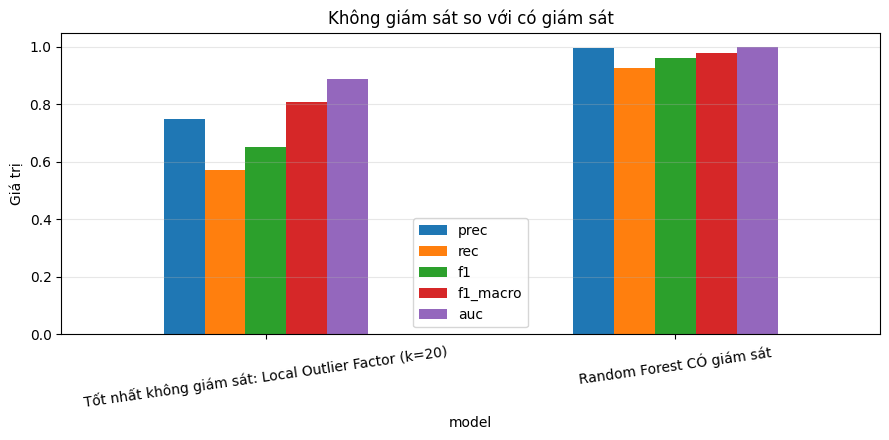

In [10]:
# Câu hỏi quan trọng: nếu ta CÓ nhãn tấn công thì mô hình tốt hơn bao nhiêu?
# Phần này huấn luyện một Random Forest có giám sát trên cùng dữ liệu nhưng
# được dùng cả nhãn tấn công, rồi so với phương pháp không giám sát tốt nhất.
#
# Đây là cách định lượng CÁI GIÁ của việc không có nhãn — con số này quyết
# định việc có nên đầu tư vào việc gán nhãn dữ liệu hay không.
X_a, X_b, y_a, y_b2 = train_test_split(X_sup, y_sup, test_size=TEST_SIZE,
                                       random_state=SEED, stratify=y_sup)
sc_sup = StandardScaler().fit(X_a)
rf = RandomForestClassifier(n_estimators=200, random_state=SEED, n_jobs=-1)
rf.fit(sc_sup.transform(X_a), y_a)
Zb = sc_sup.transform(X_b)
rf_res = evaluate(y_b2, rf.predict(Zb), rf.predict_proba(Zb)[:, 1],
                  "Random Forest CÓ giám sát")

best_unsup = cmp_df["f1"].idxmax()
print(f"Random Forest được huấn luyện trên {len(y_a):,} mẫu CÓ NHÃN "
      f"(trong đó {int(y_a.sum()):,} mẫu tấn công)")
print(f"Phương pháp không giám sát chỉ dùng {Z_fit.shape[0]:,} mẫu lành tính, "
      f"KHÔNG dùng một nhãn tấn công nào")
print()
gap = pd.DataFrame([
    dict(cmp_df.loc[best_unsup], model=f"Tốt nhất không giám sát: {best_unsup[:30]}"),
    rf_res,
]).set_index("model").round(4)
print(gap[["prec", "rec", "f1", "f1_macro", "auc"]])
print(f"\nKhoảng cách F1: {rf_res['f1'] - cmp_df.loc[best_unsup, 'f1']:+.4f} | "
      f"khoảng cách AUC: {rf_res['auc'] - cmp_df.loc[best_unsup, 'auc']:+.4f}")
print(SUPERVISED_COMMENT)

ax = gap[["prec", "rec", "f1", "f1_macro", "auc"]].plot.bar(figsize=(9, 4.5), rot=8)
ax.set_ylabel("Giá trị")
ax.set_title("Không giám sát so với có giám sát")
ax.grid(axis="y", alpha=.3)
plt.tight_layout()
plt.show()


### A8. Đánh Giá Trên Tập Held-Out (test_dataset_2)

Tập held-out sau chuẩn hóa: (10081, 37)



                                 prec     rec      f1  f1_macro     auc
model                                                                  
Isolation Forest — Test 2      0.3712  0.2506  0.2992    0.5948  0.6942
One-Class SVM — Test 2         0.8611  0.5405  0.6642    0.8067  0.8508
Local Outlier Factor — Test 2  0.8386  0.5424  0.6587    0.8032  0.8430

→ Tốt nhất trên Test 1: F1 = 0.6494
→ Tốt nhất trên Test 2 (held-out): F1 = 0.6642  (chênh +0.0148)

Confusion matrix Isolation Forest trên Test 2: TN=7762  FP=691  FN=1220  TP=408

══════════════════════════════════════════════════════════════════════
KẾT QUẢ QUAN TRỌNG NHẤT CỦA CẢ BỐN BÀI CV4.4
══════════════════════════════════════════════════════════════════════
                              Test 1       Test 2 (held-out)
  KNN (Bài 6)                  0,9521          0,3558
  Naive Bayes (Bài 7)          0,6316          0,1606
  SVM (Bài 8)                  0,9516          0,4738
  Random Forest (mốc)          0,9605         

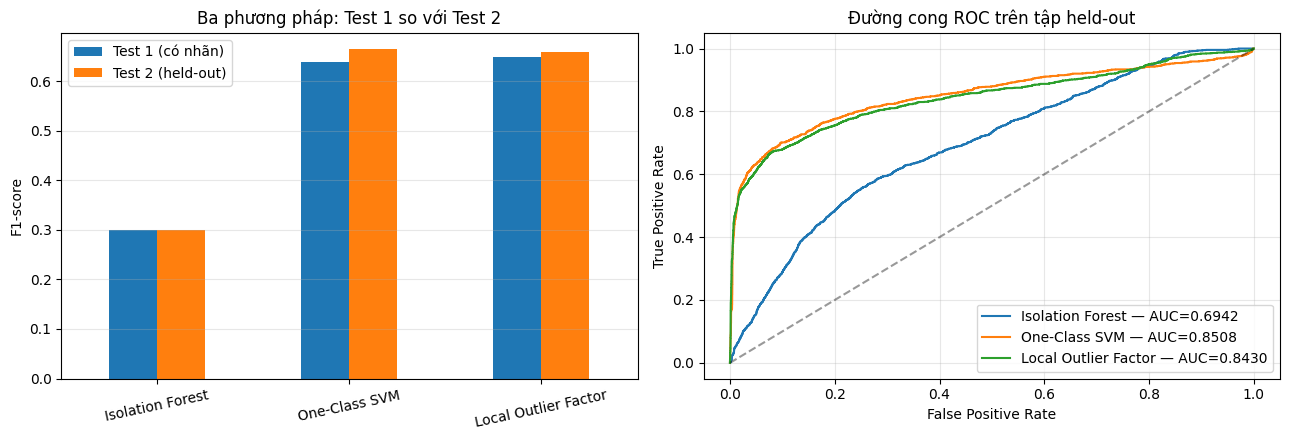

In [11]:
# Tập held-out test_dataset_2 là giai đoạn tấn công hoàn toàn khác. Với bài
# này có một điểm đáng chú ý: mô hình KHÔNG học từ nhãn tấn công nào cả, nên
# nó không thể "ghi nhớ" các cuộc tấn công của giai đoạn trước. Về lý thuyết,
# phương pháp không giám sát phải ít bị rò rỉ thời gian hơn các bài trước.
Z_ho = scaler.transform(X_ho_raw.values)
print(f"Tập held-out sau chuẩn hóa: {Z_ho.shape}")

s_ho_iso = anomaly_score(iso_best, Z_ho)
s_ho_oc = anomaly_score(oc_best, Z_ho)
s_ho_lof = anomaly_score(lof_best, Z_ho)

rows = [
    evaluate(y_ho, (s_ho_iso >= THR_ISO).astype(int), s_ho_iso,
             "Isolation Forest — Test 2"),
    evaluate(y_ho, (oc_best.predict(Z_ho) == -1).astype(int), s_ho_oc,
             "One-Class SVM — Test 2"),
    evaluate(y_ho, (lof_best.predict(Z_ho) == -1).astype(int), s_ho_lof,
             "Local Outlier Factor — Test 2"),
]
ho_df = pd.DataFrame(rows).set_index("model").round(4)
print()
print(ho_df[["prec", "rec", "f1", "f1_macro", "auc"]])

best_te = cmp_df["f1"].max()
best_ho = ho_df["f1"].max()
print(f"\n→ Tốt nhất trên Test 1: F1 = {best_te:.4f}")
print(f"→ Tốt nhất trên Test 2 (held-out): F1 = {best_ho:.4f}  "
      f"(chênh {best_ho - best_te:+.4f})")

cm_ho = confusion_matrix(y_ho, (s_ho_iso >= THR_ISO).astype(int))
tn2, fp2, fn2, tp2 = cm_ho.ravel()
print(f"\nConfusion matrix Isolation Forest trên Test 2: "
      f"TN={tn2}  FP={fp2}  FN={fn2}  TP={tp2}")
print(HELDOUT_COMMENT)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
comb = pd.DataFrame({
    "Test 1 (có nhãn)": cmp_df["f1"].values,
    "Test 2 (held-out)": ho_df["f1"].values,
}, index=["Isolation Forest", "One-Class SVM", "Local Outlier Factor"])
comb.plot.bar(ax=axes[0], rot=12)
axes[0].set_ylabel("F1-score")
axes[0].set_title("Ba phương pháp: Test 1 so với Test 2")
axes[0].grid(axis="y", alpha=.3)

for nm, sc in [("Isolation Forest", s_ho_iso), ("One-Class SVM", s_ho_oc),
               ("Local Outlier Factor", s_ho_lof)]:
    fpr, tpr, _ = roc_curve(y_ho, sc)
    axes[1].plot(fpr, tpr, label=f"{nm} — AUC={roc_auc_score(y_ho, sc):.4f}")
axes[1].plot([0, 1], [0, 1], "k--", alpha=.4)
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("Đường cong ROC trên tập held-out")
axes[1].legend()
axes[1].grid(alpha=.3)
plt.tight_layout()
plt.show()


---
## Nhận Xét & Câu Hỏi Thảo Luận

**Tổng hợp những gì bài thực hành cho thấy**

1. Đây là bài đầu tiên của CV4.4 dùng được `train_dataset.csv` (48.106 mẫu bình thường) đúng mục đích — các bài có giám sát từ Bài 1 đến Bài 8 đều phải bỏ qua file này.
2. Isolation Forest hoạt động kém (F1 0,300, AUC 0,744): nó cắt theo từng đặc trưng độc lập, trong khi tấn công ICS làm sai QUAN HỆ giữa các cảm biến.
3. One-Class SVM tốt nhất với `nu` NHỎ nhất (0,01) — ngược với hai bài tương ứng của CV4.1 và CV4.2, vì vùng vận hành bình thường của một hệ thống vật lý rất chặt chẽ.
4. LOF dẫn đầu trên Test 1 (F1 0,649, AUC 0,887) và có đỉnh rõ ở `k=20`.
5. Cả ba phương pháp đều vượt mốc tầm thường (0,193), vì tập test có tỷ lệ tấn công thực tế 10,7%.
6. **Trên tập held-out, phương pháp không giám sát KHÔNG suy giảm**: One-Class SVM 0,639 → 0,664 và LOF 0,649 → 0,659, trong khi mọi mô hình có giám sát sụt một nửa đến hai phần ba (SVM 0,952 → 0,474; KNN 0,952 → 0,356).

**Câu hỏi thảo luận**

1. Vì sao Isolation Forest kém hơn hẳn One-Class SVM và LOF trên dữ liệu cảm biến ICS? Hãy liên hệ với việc Isolation Forest cắt theo từng đặc trưng một cách độc lập.
2. `nu` tối ưu ở đây là 0,01 trong khi ở hai bài tương ứng của CV4.1 và CV4.2 là 0,2. Hãy giải thích bằng tính chất của dữ liệu vận hành một hệ thống vật lý duy nhất.
3. LOF có AUC 0,887 nhưng F1 chỉ 0,649. Hai con số này nói gì khác nhau, và bạn sẽ làm gì để F1 tiến gần hơn tới mức mà AUC hứa hẹn?
4. Đây là câu hỏi trọng tâm của bài: vì sao phương pháp không giám sát KHÔNG bị suy giảm trên tập held-out, trong khi mọi mô hình có giám sát đều sụt mạnh? Hãy trả lời bằng khái niệm rò rỉ thời gian.
5. One-Class SVM còn TĂNG nhẹ khi chuyển sang Test 2 (0,639 → 0,664). Hãy đưa ra một giải thích hợp lý cho việc hiệu năng tăng chứ không giảm.
6. Ở phần A7, Random Forest có giám sát đạt F1 0,9605 — cao gấp rưỡi phương pháp không giám sát. Nhưng trên held-out thì ngược lại. Nếu bạn chỉ được xem kết quả của phần A7, bạn sẽ ra quyết định sai như thế nào?
7. Sau bốn bài trên cùng bộ BATADAL (KNN, Naive Bayes, SVM, và phát hiện bất thường), hãy viết đề xuất kiến trúc phát hiện tấn công cho một hệ thống cấp nước thật: dùng mô hình nào, chia dữ liệu ra sao, đánh giá bằng chỉ số nào, và chấp nhận mức cảnh báo giả bao nhiêu.
